# Compressed sensing of audio, images

Executed in python 3.14.3


In [22]:
import os, sys

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from scipy.fftpack import dct, idct
from scipy.ndimage import zoom
from scipy.fftpack import dct, idct, fft, fft2, ifft, ifft2
import cvxpy as cp

In [2]:
# taken from https://github.com/avirmaux/CoSaMP/tree/master, in lieu of finding a package that works

def cosamp(phi, u, s, epsilon=1e-10, max_iter=1000):
    """
    Return an `s`-sparse approximation of the target signal
    Input:
        - phi, sampling matrix
        - u, noisy sample vector
        - s, sparsity
    """
    a = np.zeros(phi.shape[1])
    v = u
    it = 0 # count
    halt = False
    while not halt:
        it += 1
        print("Iteration {}\r".format(it), end="")
        
        y = np.dot(np.transpose(phi), v)
        omega = np.argsort(y)[-(2*s):] # large components
        omega = np.union1d(omega, a.nonzero()[0]) # use set instead?
        phiT = phi[:, omega]
        b = np.zeros(phi.shape[1])
        # Solve Least Square
        b[omega], _, _, _ = np.linalg.lstsq(phiT, u)
        
        # Get new estimate
        b[np.argsort(b)[:-s]] = 0
        a = b
        
        # Halt criterion
        v_old = v
        v = u - np.dot(phi, a)

        halt = (np.linalg.norm(v - v_old) < epsilon) or \
            np.linalg.norm(v) < epsilon or \
            it > max_iter
        
    return a

## 1 - audio signals

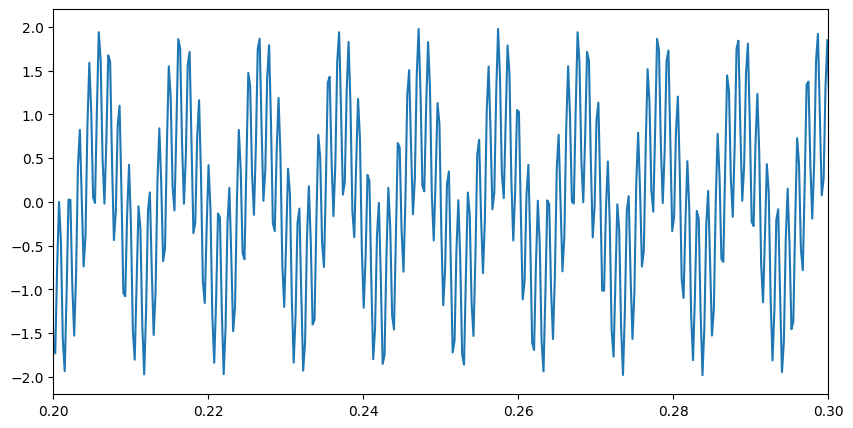

In [3]:
NUM_POINTS = 2**12

t = np.linspace(0, 1, NUM_POINTS)

# change below to change the specific form. this is the same as the textbook - 2 tone signal
x = np.cos(2*97*np.pi*t) + np.cos(2*777*np.pi*t)

plt.figure(figsize=(10,5))
plt.plot(t, x)
plt.xlim(0.2, 0.3)
plt.show()

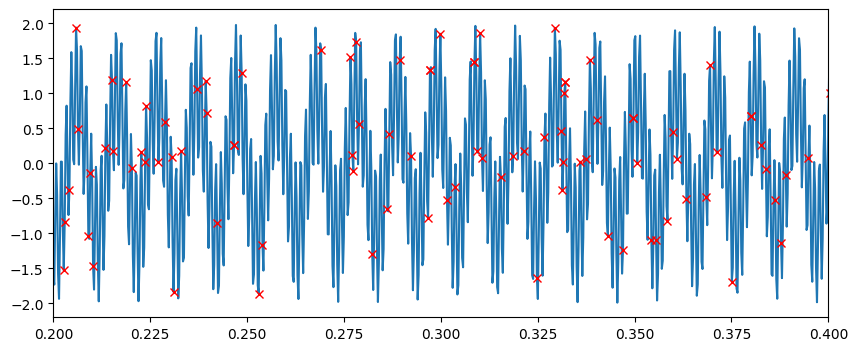

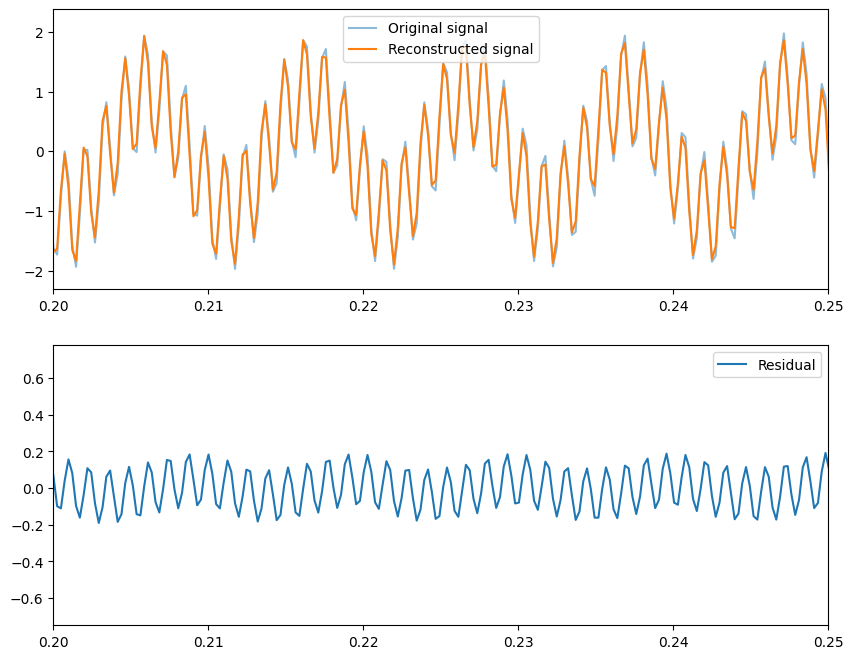

In [4]:
xt = np.fft.fft(x)
# Power spectral density
PSD = xt * np.conjugate(xt) / NUM_POINTS

# take a random sample in line with sample_count
sample_count = 500
sample_count = int(sample_count) # ensure no float

selections = np.round(np.random.rand(sample_count, 1) * NUM_POINTS)
selections = [int(e[0]) for e in selections]

y = x[selections]
plt.figure(figsize=(10, 4))
plt.plot(t, x)
plt.plot(t[selections], y, 'x', color='red')
plt.xlim(0.2, 0.4)
plt.show()

# create generic Psi
# make a NxN identity matrix
identity = np.eye(NUM_POINTS, NUM_POINTS)
# implement discrete cosign transform on identity matrix (from scipy.fftpack)
psi = dct(identity)
# take theta, our p * n matrix featuring what measurements are made 
# selections is a vector representing where samples have been made
theta = psi[selections, :]

# apply cosamp algorithm
s = cosamp(theta, y, 4)

x_r = idct(s)
lim = (0.2, 0.25)
plt.figure(figsize=(10, 8))
plt.subplot(2, 1, 1)
plt.plot(t, x, alpha=0.5, label='Original signal')
plt.plot(t, x_r, label='Reconstructed signal')
plt.legend()
plt.xlim(*lim)
plt.subplot(2, 1, 2)
plt.plot(t, x-x_r, label='Residual')
plt.legend()
plt.xlim(*lim)
plt.show()


## 2 - formalising 

In [5]:
def take_samples(x, samples):
    '''
    returns a list of sampled indicies for X, such that x[indicies] returns only those samples'''
    selections = np.round(np.random.rand(samples, 1) * len(x)-1)
    selections = [int(e[0]) for e in selections]
    return selections

def reconstruct(y, n, p, sparsity=5, epsilon=1e-10, max_iter=1000, mode='cosamp'):
    '''
    for a sampling y, with n maximum spaces in the dataset and sample vector p, computes and returns the reconstructed signal x'''
    psi = dct(np.eye(n, n))
    theta = psi[p, :]
    if mode=='cosamp':
        s = cosamp(theta, y, sparsity, epsilon, max_iter)
    elif mode=='cvx':
        s_l1 = cp.Variable((n, 1))
        obj = cp.Minimize(cp.norm(s_l1, 1))
        cons = [theta @ s_l1 == y]
        problem = cp.Problem(obj, cons)
        problem.solve()
        s = s_l1.value


    return idct(s)

## 3 - image compression

i've got a directory `./testdata/` with various images that i've set not to include into the git repo - up to you to include your own data.

In [6]:
def plot_nice_image(img, pow=None, darkBack = True, invert=False, cmap:tuple = None):
    cs = ('Reds', 'Greens', 'Blues')
    if cmap != None:
        cs = cmap
    if darkBack:
        backing = np.ones(shape=(img.shape[0], img.shape[0]))
        plt.imshow(backing, cmap='gray')
    for n in range(3):
        imgsel = img[:,:,n]
        if darkBack:
            achannel = img[:,:,n]
            achannel = np.where(achannel > 0, achannel, 0)
            if pow != None:
                if type(pow) in (int, float):
                    achannel = np.pow(achannel, pow)
                else:
                    achannel = np.pow(achannel, pow[n])
            if invert:
                imgsel = 1-imgsel
            plt.imshow(imgsel, cmap=cs[n], alpha=achannel)
        else:
            if invert:
                imgsel = 1-imgsel
            plt.imshow(imgsel, cmap=cs[n], alpha=0.5)

def swizzle_image(image):
    # inverts a 3, X, Y image into X, Y, 3
    a, b, c = image
    
    size = a.shape[0] # should be consistent
    a, b, c = np.ravel(a), np.ravel(b), np.ravel(c)
    
    outp = [ [i, j, k] for i, j, k in zip(a, b, c)]
    outp = np.array(outp)
    outp = np.reshape(outp, (size, size, 3))
    return outp

def unswizzle_image(image):
    # converts an XY3 image into 3XY
    image_rgbs = [image[:,:,i] for i in range(3)]
    raw = np.ndarray((3, image.shape[0], image.shape[1]))
    for i in range(3):
        raw[i] = image_rgbs[i]
    return raw

def decondense_frames(image):
    # decondenses a swizzled image into a list of 3 frames
    return [image[:,:,i] for i in range(3)]

def condense_frames(frames):
    # condenses multiple frames into unswizzled format
    raw = np.ndarray((3, frames[0].shape[0], frames[0].shape[1]))
    for i in range(3):
        raw[i] = frames[i]
    return raw.astype(int)

image is (720, 1280, 3) along first 2 axis


(720, 720)


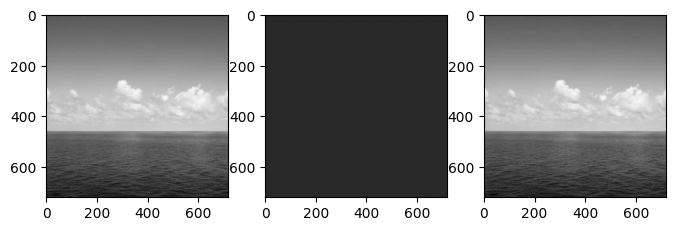

(720, 720)
(518400,) len with max 518399
recon -480.75041467991184, 82.55669068724814
recon 0.0, 1.0


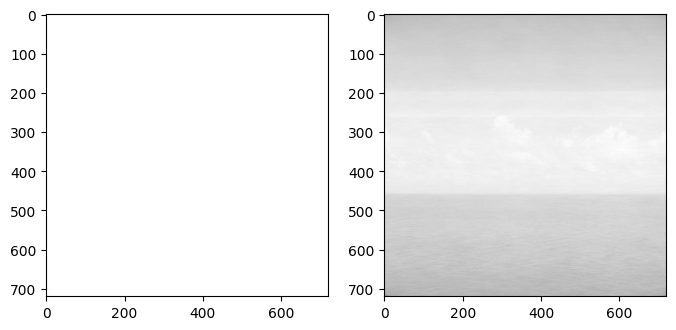

In [7]:
# test against an image
def take_samples(length, samples):
    '''
    returns a list of sampled indicies for X, such that x[indicies] returns only those samples'''
    selections = np.round(np.random.rand(samples, 1) * length-1)
    selections = [int(e[0]) for e in selections]
    return selections

def make_gray(rgb):
    # turns (x,y,3) into (x,y,1)
    r, g, b = rgb[:,:,0], rgb[:,:,1], rgb[:,:,2]
    gray = 0.2989 * r + 0.5870 * g + 0.1140 * b
    
    return gray

image = plt.imread(f'./testdata/ocean.jpg')
print(f'image is {image.shape} along first 2 axis')

# crop image down to central square
image = image[:,280:1000,:]
# image = np.sqrt(np.pow(image[:,:,0], 2) + np.pow(image[:,:,1], 2) + np.pow(image[:,:,2], 2))
image = make_gray(image)
print(image.shape)

image_t =fft2(image)
plt.figure(figsize=(8, 4))
plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray')
plt.subplot(1, 3, 2)
plt.imshow(np.real(image_t), cmap='gray')
plt.subplot(1, 3, 3)
plt.imshow(np.real(ifft2(image_t)).astype(int), cmap='gray')
plt.show()

# discard some random values from image_t

x, y = image_t.shape[0:2]
N = x * y
image_t_len = np.ravel(image_t)

sample_percent = 0.95
sample_count = int(N * sample_percent)
# samples = take_samples(N, sample_count)
print(image_t.shape)
min_els = np.argsort(image_t_len)
print(f'{min_els.shape} len with max {np.max(min_els)}')
samples = min_els[0:sample_count]


image_t_res = np.zeros(N)
image_t_res[samples] = 1
image_t_res = np.reshape(image_t_res, (x, y))
image_t_res = image_t_res * image_t

plt.figure(figsize=(8, 6))
plt.subplot(1, 2, 1)
plt.imshow(np.real(image_t_res), cmap='gray')
plt.subplot(1, 2, 2)
recon_image = np.real(ifft2(image_t_res))
print(f'recon {np.min(recon_image)}, {np.max(recon_image)}')
recon_image = (recon_image - np.min(recon_image)) / (np.max(recon_image) - np.min(recon_image))
print(f'recon {np.min(recon_image)}, {np.max(recon_image)}')

plt.imshow(recon_image, cmap='gray')
plt.show()


In [8]:
def square_crop(image):
    x, y, _ = image.shape
    if y > x:
        # crop along y (1) to make it only =x
        start = int((y/2) - (x/2))
        end = int((y/2) + (x/2))
        image = image[:,start:end,:]
    elif x > y:
        # crop along x (0) to make it only =y
        start = int((x/2) - (y/2))
        end = int((x/2) + (y/2))
        image = image[start:end,:,:]
    return image

## Crackpot ring-imaging

Can we represent an image as a more contiguous data format to allow interpolation between any two datapoints?
Ring-functions - Mapping a image as increasing rings heading outwards from the center axis of the image.

In [ ]:
def ring_func(image, r_dens:float=None, theta_dens:float=None, use_local_radius:bool=False, use_actual_densities:bool = False):
    '''Taken a square-crop image (monochannel) and the function density coefficient (multiplied by the radius) (defaults to 2 if None), returns ring function data per ring.'''
    if len(image.shape) > 2 and image.shape[2] != 1:
        print(f'Not a mono channel image! ({image.shape})')
        return None

    X, Y = image.shape[0:2]
    if X != Y:
        print(f'Not a square image! ({X}, {Y})')
        return None
    
    radius = Y * 0.5

    if r_dens == None:
        r_dens = 2
    if theta_dens == None:
        theta_dens = 2
    

    def map_coord(r, theta)->tuple[int, int]:
        x = r + (np.cos(theta) * r)
        y = r + (np.sin(theta) * r)

        x = np.round(x).astype(int)
        y = np.round(y).astype(int)

        x = np.where(x >= len(theta), len(theta)-1, x)
        y = np.where(y >= len(theta), len(theta)-1, y)

        return x, y

    r_samps = int(r_dens * radius)
    th_samps = int(theta_dens * radius)
    R = np.linspace(0, radius-1, r_samps)
    THETA = np.linspace(0, 2*np.pi, th_samps)
    theta_dump = []

    # gets each value as a function of theta at a given R
    # stows into a object of shape (R, THETA)
    res = []
    for r in R:
        if use_local_radius:
            THETA = np.linspace(0, 2*np.pi, int(theta_dens * r))
            theta_dump.append(THETA)
        coord = map_coord(r, THETA)
        # coord = np.where(coord >= len(coord), len(coord)-1, coord)
        ring = image[coord]
        res.append(ring)

    if not use_local_radius:
        res = np.array(res)
    if use_local_radius:
        THETA = theta_dump
    
    return res, R, THETA

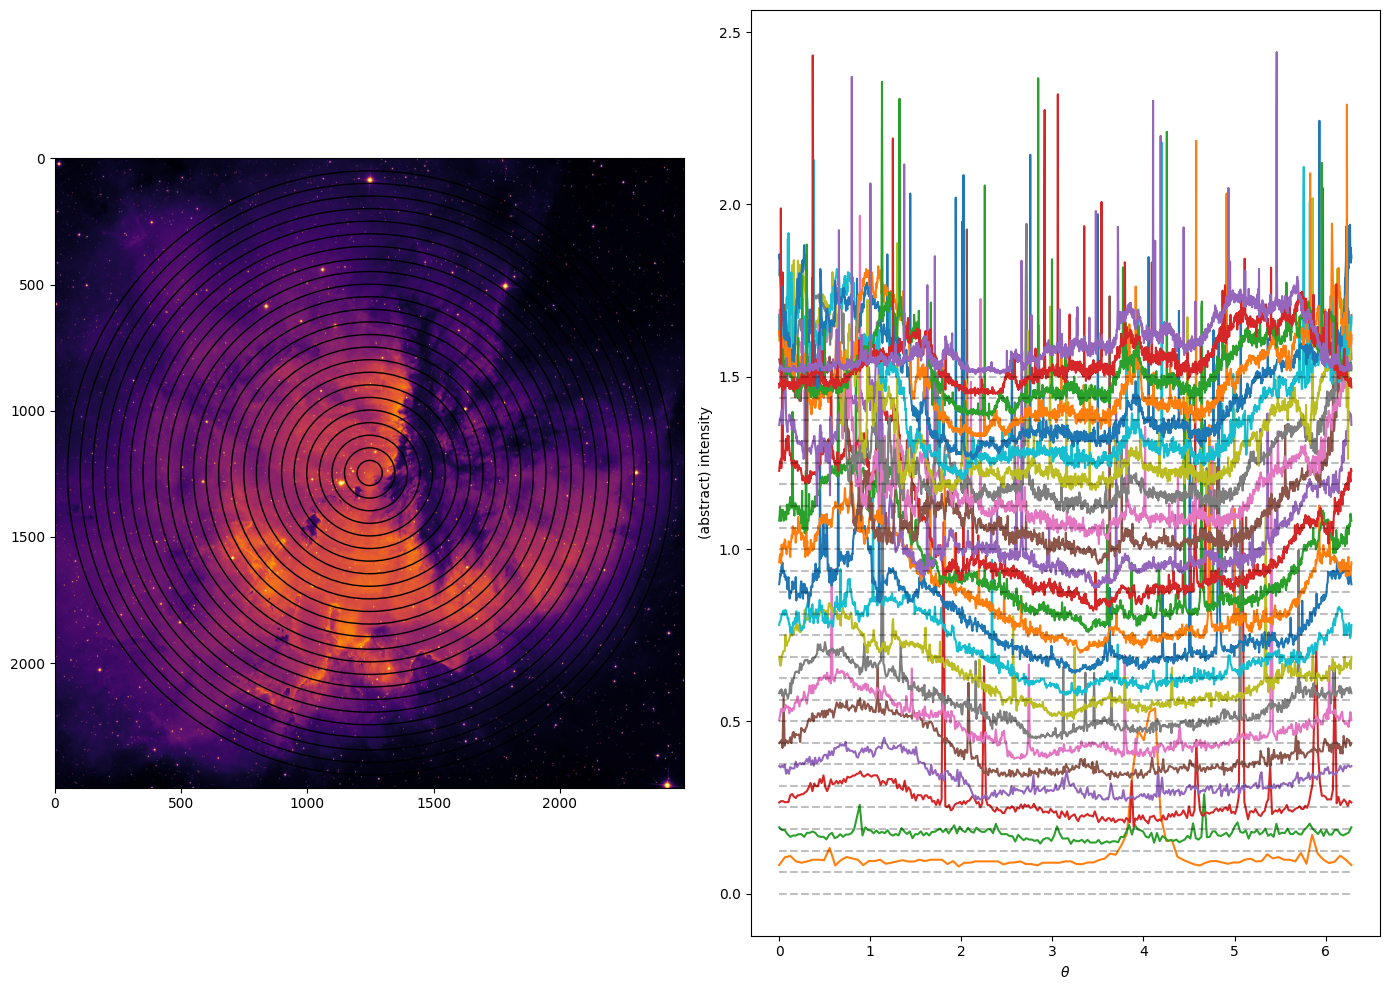

In [28]:
image = make_gray(square_crop(plt.imread(f'./testdata/space.jpg')))
image = image / 256

image_radius = image.shape[0]/2
target_rings = 25
factor = target_rings / image_radius
radius_step = image_radius / target_rings

rings, R, thetas = ring_func(image, r_dens=factor, use_local_radius=True)

plt.figure(figsize=(14, 10))
plt.subplot(1, 2, 1)
plt.imshow(image, cmap='inferno')

ax = plt.gca()

for n in range(target_rings):
    circ = Circle((image_radius, image_radius), n*radius_step, fill=False)
    ax.add_patch(circ)

# plt.plot(image.shape[0]/2, image.shape[1]/2, 'o', color='red')
plt.subplot(1, 2, 2)

for ring, r, theta, n in zip(rings, R, thetas, range(len(thetas))):
    plt.plot(theta, ring+(n/16), label=f'Layer {r:.2e} ({len(theta)} datapoints)')
plt.hlines(np.arange(0, len(thetas)) / 16, 0, 2*np.pi, colors='k', linestyles='dashed', alpha=0.25)
# plt.legend(bbox_to_anchor=(1.05, 1),loc='upper left', borderaxespad=0.)
plt.xlabel(f'$\\theta$')
plt.ylabel(f'(abstract) intensity')
plt.tight_layout()
plt.show()